
# Combined Lagrangian of the cascade: scalarized QCQP with a positive definite dual

Bound on the scattered power $P = \tfrac12 I^H R_0 I$ of a structure carved out of the copper 2:1 plate (`*_patch21ka1.txt`, $ka = 1$ at 2.45 GHz,
plane wave $E_0 = 1$ kV/m), in the RWG basis with $Z_\mathrm{mat} = Z_s L$ and the scattered voltage $x = V_\mathrm{sca} = -Z_0 I$ as the variable.

**Why combine.** The GCD Lagrangian of the scattering dual is in the hard case (min/max eigenvalue $\sim 10^{-13}$), so its dual current
$x^\star = L^{\star -1} S$ is not unique. Between GCD realizations it changed by 54–57 %, although the multipliers agreed to $10^{-4}$. The cascade
(`nullspaceCascade.ipynb`) fixes the kernel component level by level: field, then current. Its levels are, however, hard cases again.

**Combined problem.** The lexicographic cascade is replaced by its scalarization, a single QCQP in the full space,
$$\max_x\; P(x) - \tau_2\, \|V + x\|^2 - \tau_3\, \|W x\|^2 \quad \text{s.t. the projector constraints } \operatorname{Re}\Big(\sum_i \overline{p_i}\, w_i\Big) = 0 ,$$
with $A_0 = -\tfrac12 W^H R_0 W + \tau_2 + \tau_3 W^H W$, $s_0 = -\tau_2 V$ and $c_0 = -\tau_2 \|V\|^2$. Its Lagrangian is the combined Lagrange matrix of all levels,
$$L_c = L_1(\lambda) + \tau_2\, 1 + \tau_3\, W^H W ,$$
- **Joint optimization.** The multipliers of all constraints are optimized jointly, by the global bound and then GCD on the scalarized problem
  (`run_gcd`, the library's local power projectors).
- **Definiteness.** For $\tau_2, \tau_3 > 0$ the added terms are positive definite and push $L_c$ away from the PSD boundary. If the dual optimum is
  interior (easy case), the dual gradient vanishes there: the dual current is feasible and unique, and strong duality holds.
- **Bound.** The dual $D_c$ bounds $P - \tau_2 F - \tau_3 \|I\|^2$ for every structure, so $P \leq D_c + \tau_2 F + \tau_3 \|I\|^2$ for a structure with field $F$
  and current $I$.

**Sensitivity.** A perturbation $\delta\lambda$ of the multipliers moves $x = L_c^{-1} S_c$ by about $\operatorname{cond}(L_c)\,\delta\lambda$, so a definite $L_c$ should make
the dual current insensitive to the GCD randomness.

**Weights.** They are relative to the global scattering solution $x_g$, with $\tau_2 = t\, D_g / \|V + x_g\|^2$ and $\tau_3 = 0.1\, t\, D_g / \|W x_g\|^2$ (the current
weighted one order below the field, as in the cascade). The sweep is $t = 0$ (plain scattering GCD), $10^{-3}$, $10^{-2}$, $10^{-1}$; each $t$ runs
three GCD realizations.


In [1]:
import contextlib
import copy
import io
import time

import matplotlib.pyplot as plt
import numpy as np
import scipy.io as sio
import scipy.linalg as la
import scipy.sparse as sp
from matplotlib.collections import LineCollection, PolyCollection
from matplotlib.colors import LogNorm
from scipy.optimize import least_squares

from dolphindes.cvxopt import DenseSharedProjQCQP, OptimizationHyperparameters
from dolphindes.cvxopt.gcd import GCDHyperparameters

In [2]:
matrixSet = "patch21ka1" # copper 2:1 plate, ka = 1; omW and the mesh exist for this set only (exportOmWpatch21ka1.m)

# Physical constants
epsilon_0 = 8.854e-12 # F/m
mu_0 = 4e-7 * np.pi # H/m
c = 1/np.sqrt(epsilon_0 * mu_0) # speed of light in vacuum
eta_0 = np.sqrt(mu_0/epsilon_0) # free-space impedance

E0 = 1e3 # plane wave amplitude in V/m

frequency = 2.45e9 # frequency in Hz
omega = 2 * np.pi * frequency # angular frequency

copper_conductivity = 5.96e7 # S/m
delta = np.sqrt(2 / (omega * mu_0 * copper_conductivity)) # skin depth in m
Zs = (1 + 1j) / (copper_conductivity * delta) # surface impedance
print(f"Surface impedance: {Zs} Ω")

Surface impedance: (0.012739130327240646+0.012739130327240646j) Ω


In [3]:
def Msym(M):
    return(0.5*(M.conj().T + M))

# Load matrices from text files (original RWG basis, no Cholesky transformation)
Lmat = np.loadtxt(f"Lmat_{matrixSet}.txt", delimiter=',') # lossy matrix
R0 = Msym(np.loadtxt(f"R0_{matrixSet}.txt", delimiter=',')) # radiated power matrix
X0 = Msym(np.loadtxt(f"X0_{matrixSet}.txt", delimiter=',')) # reactive power matrix
Vinc = E0*np.loadtxt(f"V_{matrixSet}.txt", delimiter=',').astype(complex) # voltage excitation vector

Ndes = Lmat.shape[0] # number of design variables
print(f"Matrix set: {matrixSet}, number of design variables: {Ndes}")

Zmat = Zs * Lmat # material impedance matrix (non-diagonal)
Z0 = R0 + 1j*X0 # free-space impedance matrix
Ztot = Z0 + Zmat # total impedance matrix
Ldiag = np.diag(Lmat).copy() # diagonal of the lossy matrix

def evalObj(Ivec):
    # scattered (radiated) power
    return(0.5*np.real(Ivec.conj() @ R0 @ Ivec))

# full plate performance
Ifull = np.linalg.solve(Ztot, Vinc)
Pfull = evalObj(Ifull)
print(f"Objective for full plate: {Pfull:.6e} W")

# reference: lossless resonant electric dipole, sigma_sca = 3 lambda^2 / (2 pi)
Pdip = 3*(c/frequency)**2/(2*np.pi) * E0**2/(2*eta_0)
print(f"resonant dipole scattered power: {Pdip:.4f} W")

Matrix set: patch21ka1, number of design variables: 233
Objective for full plate: 4.114174e-02 W
resonant dipole scattered power: 9.4884 W


In [4]:
# mesh of the operators (exportOmWpatch21ka1.m): bf[n] = [T+, T-, edge node 1, edge node 2], 0 based
mesh = sio.loadmat(f"mesh_{matrixSet}.mat")
nodes, tria, bf = mesh["nodes"], mesh["triangles"], mesh["bf"]
edgeLen = np.linalg.norm(nodes[bf[:, 2]] - nodes[bf[:, 3]], axis=1)
e1, e2 = nodes[tria[:, 1]] - nodes[tria[:, 0]], nodes[tria[:, 2]] - nodes[tria[:, 0]]
triArea = 0.5*np.abs(e1[:, 0]*e2[:, 1] - e1[:, 1]*e2[:, 0])
triCent = nodes[tria].mean(axis=1)
freeNode = np.array([[np.setdiff1d(tria[t], bf[n, 2:])[0] for t in bf[n, :2]] for n in range(Ndes)]) # free vertices of T+, T-
print(f"{len(nodes)} nodes, {len(tria)} triangles, plate {np.ptp(nodes[:, 0])*1e3:.2f} x {np.ptp(nodes[:, 1])*1e3:.2f} mm, "
      f"Lmat_nn = 0.481 l_n^2 (equilateral RWG): max rel. error {np.max(np.abs(Ldiag/(5/(6*np.sqrt(3))*edgeLen**2) - 1)):.1e}")

def currentDensity(I):
    # RWG current density at the triangle centroids, J = I_n l_n rho / (2 A)
    J = np.zeros((len(tria), 2), dtype=complex)
    for s, sgn in [(0, 1), (1, -1)]:
        rho = sgn*(triCent[bf[:, s]] - nodes[freeNode[:, s]])
        np.add.at(J, bf[:, s], (I*edgeLen/(2*triArea[bf[:, s]]))[:, None]*rho)
    return J

def plotStructure(ax, keep, I, title=""):
    # metal triangles colored by |J| (log); removed RWG functions between metal triangles are slots (red), void triangles white
    metal = np.zeros(len(tria), dtype=bool)
    metal[bf[keep, :2].ravel()] = True
    J = np.linalg.norm(np.abs(currentDensity(I)), axis=1)
    pc = PolyCollection(nodes[tria[metal]], array=np.maximum(J[metal], 1e-3*J.max()), cmap='viridis',
                        norm=LogNorm(1e-3*J.max(), J.max()), edgecolors='none')
    ax.add_collection(pc)
    ax.add_collection(PolyCollection(nodes[tria[~metal]], facecolors='white', edgecolors='0.85', linewidths=0.3))
    slot = ~keep & metal[bf[:, 0]] & metal[bf[:, 1]]
    ax.add_collection(LineCollection(nodes[bf[slot, 2:]], colors='r', linewidths=1.5))
    ax.set_xlim(nodes[:, 0].min(), nodes[:, 0].max()); ax.set_ylim(nodes[:, 1].min(), nodes[:, 1].max())
    ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([]); ax.set_title(title, fontsize=9)
    return pc

def plotDensity(ax, d, title=""):
    # inferred density on the RWG edges
    lc = LineCollection(nodes[bf[:, 2:]], array=np.log10(np.maximum(d, 1e-6)), cmap='viridis', linewidths=2.5)
    lc.set_clim(-6, 0)
    ax.add_collection(lc)
    ax.set_xlim(nodes[:, 0].min(), nodes[:, 0].max()); ax.set_ylim(nodes[:, 1].min(), nodes[:, 1].max())
    ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([]); ax.set_title(title, fontsize=9)
    return lc

def plotComplexDensity(axes, d, title=""):
    # complex density on the RWG edges: Re d (1 metal, 0 void) and Im d (0 for any structure), on a common symmetric scale
    dmax = np.quantile(np.abs(d), 0.99)
    for ax, part, name in [(axes[0], d.real, "Re d"), (axes[1], d.imag, "Im d")]:
        lc = LineCollection(nodes[bf[:, 2:]], array=part, cmap='RdBu_r', linewidths=2.5)
        lc.set_clim(-dmax, dmax)
        ax.add_collection(lc)
        ax.set_xlim(nodes[:, 0].min(), nodes[:, 0].max()); ax.set_ylim(nodes[:, 1].min(), nodes[:, 1].max())
        ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([]); ax.set_title(f"{title}: {name}, scale \u00b1{dmax:.1e}", fontsize=8)
        plt.colorbar(lc, ax=ax, shrink=0.8, format='%.0e')
    return lc

104 nodes, 168 triangles, plate 35.05 x 17.00 mm, Lmat_nn = 0.481 l_n^2 (equilateral RWG): max rel. error 2.6e-14


## Scattering QCQP, global and GCD bounds

As in `maxScatFixQ.ipynb`: $A_0 = -\tfrac12 W^H R_0 W$ with $W = Z_0^{-1}$, $I = -W x$, and the projector constraints
$\operatorname{Re}(-x^H A_1 P A_2 x + 2 x^H A_2^H P^H s_1) = 0$ with $A_1 = 1 + W^H Z_\mathrm{mat}^H$, $A_2 = W$, $s_1 = -\tfrac12 V$, i.e.
$\operatorname{Re}\sum_i p_i^* w_i = 0$, $w_i = I_i^*(V - Z_\mathrm{tot} I)_i$. The global bound uses $p = \mathbf 1$ and $p = j\mathbf 1$; GCD adds
two diagonal projectors per iteration (20 iterations, no merging). GCD is slightly non-deterministic (ARPACK starts and the random
`Pstruct` coefficients).

In [5]:
print(f"cond(Z0) = {np.linalg.cond(Z0):.3e}")
W = np.linalg.inv(Z0) # Z0^{-1}
WH = W.conj().T

Obj = -0.5 * Msym(WH @ R0 @ W)
obj = np.zeros(Ndes, dtype=complex)
obj0 = 0.0
A1 = np.eye(Ndes) + WH @ Zmat.conj().T
A2 = W
s1 = -0.5 * Vinc

def VtoI(Vsca):
    return(-W @ Vsca)

def localViolation(I):
    # pointwise w_i = I_i^* (V - Ztot I)_i, zero for any structure made of enabled basis functions
    return(np.conj(I)*(Vinc - Ztot @ I))

def constraintRes(Q, x):
    # c_k(x) = Re(-x^H A_k x + 2 x^H F_k) + c_k for all constraints (W), zero for a feasible x
    res = np.real(-x.conj() @ Q._allA_at_v(x) + 2*x.conj() @ Q.Fs)
    res[Q.n_proj_constr:] += Q.c_2j
    return res

def lagSpectrum(Q):
    return np.linalg.eigvalsh(Msym(Q._get_total_A(Q.current_lags)))

opt_params = OptimizationHyperparameters(opttol=1e-8,
    gradConverge=True,
    min_inner_iter=10,
    max_restart=20,
    penalty_ratio=1e-2,
    penalty_reduction=0.1,
    break_iter_period=5,
    verbose=0)

np.random.seed(0)
PlistGlob = [sp.diags(q*np.ones(Ndes, dtype=complex)) for q in [1, 1j]] # global real and reactive power
Qglob = DenseSharedProjQCQP(Obj, obj, obj0, A1, s1, PlistGlob, A2=A2, verbose=0)
Qglob.solve_current_dual_problem(method='newton', init_lags=np.array([1.0, 0.0]), opt_params=opt_params)

Ngcd = 20 # number of GCD iterations
Qgcd = copy.deepcopy(Qglob)
gcd_params = GCDHyperparameters(max_proj_cstrt_num=2 + 2*Ngcd,
    max_gcd_iter_num=Ngcd,
    gcd_iter_period=Ngcd + 1, # no early termination
    opt_params=opt_params)
t1 = time.time()
with contextlib.redirect_stdout(io.StringIO()): # silence the per-iteration GCD output
    Qgcd.run_gcd(gcd_params)
print(f"GCD: {time.time() - t1:.1f}s")

for name, Q in [("global", Qglob), (f"GCD {Ngcd}", Qgcd)]:
    lam = lagSpectrum(Q)
    I = VtoI(Q.current_xstar)
    print(f"{name}: D {Q.current_dual:.6e} W ({Q.current_dual/Pdip:.2f} x resonant dipole), {Q.n_proj_constr} constraints, "
          f"min/max eig L* {lam[0]/lam[-1]:.1e}, ||c(x*)||/D {np.linalg.norm(constraintRes(Q, Q.current_xstar))/Q.current_dual:.1e}, "
          f"max|w_i|/|I^H V| {np.abs(localViolation(I)).max()/np.abs(I.conj() @ Vinc):.1e}")

cond(Z0) = 6.327e+02


GCD: 35.2s
global: D 1.847944e+01 W (1.95 x resonant dipole), 2 constraints, min/max eig L* 8.7e-06, ||c(x*)||/D 2.3e-04, max|w_i|/|I^H V| 4.0e+01
GCD 20: D 1.773651e+01 W (1.87 x resonant dipole), 42 constraints, min/max eig L* 1.3e-13, ||c(x*)||/D 4.9e-03, max|w_i|/|I^H V| 5.9e+01


## Scalarized QCQP and the $\tau$ sweep

In [6]:
def fieldOf(x):
    return np.linalg.norm(Vinc + x)**2

def currentOf(x):
    return np.linalg.norm(W @ x)**2

xg = Qglob.current_xstar
Dg = Qglob.current_dual
Fg, Ig = fieldOf(xg), currentOf(xg)

def scalarizedQCQP(t):
    tau2, tau3 = t*Dg/Fg, 0.1*t*Dg/Ig
    A0 = Obj + tau2*np.eye(Ndes) + tau3*(WH @ W)
    Q = DenseSharedProjQCQP(A0, -tau2*Vinc, -tau2*np.linalg.norm(Vinc)**2, A1, s1, PlistGlob, A2=A2, verbose=0)
    return Q, tau2, tau3

def solveScalarized(t, seed):
    np.random.seed(seed)
    Q, tau2, tau3 = scalarizedQCQP(t)
    Q.solve_current_dual_problem(method='newton', init_lags=np.array([1.0, 0.0]), opt_params=opt_params)
    Dglob = Q.current_dual
    with contextlib.redirect_stdout(io.StringIO()):
        Q.run_gcd(gcd_params)
    return Q, tau2, tau3, Dglob

def combinedReport(t, Q, tau2, tau3, Dglob):
    x = Q.current_xstar
    I = VtoI(x)
    lam = lagSpectrum(Q)
    P, F, Isq = evalObj(I), fieldOf(x), currentOf(x)
    res = constraintRes(Q, x)
    return dict(t=t, x=x, Q=Q, D=Q.current_dual, Dglob=Dglob, P=P, F=F, Isq=Isq, lamRatio=lam[0]/lam[-1], lamMin=lam[0],
                attained=P - tau2*F - tau3*Isq, res=np.linalg.norm(res)/abs(Q.current_dual),
                cGlob=np.linalg.norm(constraintRes(Qglob, x))/Qgcd.current_dual,
                wmax=np.abs(localViolation(I)).max()/np.abs(I.conj() @ Vinc), tau2=tau2, tau3=tau3)

tSweep = [0.0, 1e-3, 1e-2, 1e-1]
seeds = [0, 1, 2]
sweep = {}
for t in tSweep:
    sweep[t] = []
    for seed in seeds:
        t1 = time.time()
        r = combinedReport(t, *solveScalarized(t, seed))
        sweep[t].append(r)
        print(f"t {t:.0e}, seed {seed} ({time.time() - t1:.0f}s): D_c {r['D']:.6f} W (global {r['Dglob']:.6f}), attained P - tau F - tau |I|^2 {r['attained']:.6f}, "
              f"P {r['P']:.4f} W (P/D_GCD {r['P']/Qgcd.current_dual:.4f}), tau2 F {r['tau2']*r['F']:.4f} W, tau3 |I|^2 {r['tau3']*r['Isq']:.4f} W, "
              f"min/max eig L_c {r['lamRatio']:.1e}, ||c||/|D| {r['res']:.1e}, ||c_global||/D {r['cGlob']:.1e}, max|w_i|/|I^H V| {r['wmax']:.1e}", flush=True)

t 0e+00, seed 0 (35s): D_c 17.735815 W (global 18.479440), attained P - tau F - tau |I|^2 17.735616, P 17.7356 W (P/D_GCD 0.9999), tau2 F 0.0000 W, tau3 |I|^2 0.0000 W, min/max eig L_c 9.3e-14, ||c||/|D| 6.9e-03, ||c_global||/D 2.5e+02, max|w_i|/|I^H V| 4.1e+01


t 0e+00, seed 1 (36s): D_c 17.740333 W (global 18.479440), attained P - tau F - tau |I|^2 17.740354, P 17.7404 W (P/D_GCD 1.0002), tau2 F 0.0000 W, tau3 |I|^2 0.0000 W, min/max eig L_c 9.5e-14, ||c||/|D| 6.1e-03, ||c_global||/D 2.2e+02, max|w_i|/|I^H V| 4.6e+01


t 0e+00, seed 2 (35s): D_c 17.736505 W (global 18.479440), attained P - tau F - tau |I|^2 17.736176, P 17.7362 W (P/D_GCD 1.0000), tau2 F 0.0000 W, tau3 |I|^2 0.0000 W, min/max eig L_c 9.4e-14, ||c||/|D| 6.1e-03, ||c_global||/D 2.4e+02, max|w_i|/|I^H V| 4.2e+01


t 1e-03, seed 0 (30s): D_c 17.679979 W (global 18.459454), attained P - tau F - tau |I|^2 17.695754, P 17.7249 W (P/D_GCD 0.9993), tau2 F 0.0274 W, tau3 |I|^2 0.0018 W, min/max eig L_c 1.4e-13, ||c||/|D| 6.9e-03, ||c_global||/D 1.8e+02, max|w_i|/|I^H V| 3.2e+01


t 1e-03, seed 1 (29s): D_c 17.682491 W (global 18.459454), attained P - tau F - tau |I|^2 17.699473, P 17.7271 W (P/D_GCD 0.9995), tau2 F 0.0259 W, tau3 |I|^2 0.0018 W, min/max eig L_c 1.4e-13, ||c||/|D| 8.2e-03, ||c_global||/D 1.9e+02, max|w_i|/|I^H V| 4.4e+01


...

t 1e-02, seed 1 (41s): D_c 17.363921 W (global 18.302002), attained P - tau F - tau |I|^2 17.520271, P 17.6435 W (P/D_GCD 0.9948), tau2 F 0.1070 W, tau3 |I|^2 0.0161 W, min/max eig L_c 1.5e-13, ||c||/|D| 7.6e-03, ||c_global||/D 2.9e+02, max|w_i|/|I^H V| 2.0e+01


t 1e-02, seed 2 (39s): D_c 17.365927 W (global 18.302002), attained P - tau F - tau |I|^2 17.540359, P 17.6474 W (P/D_GCD 0.9950), tau2 F 0.0909 W, tau3 |I|^2 0.0161 W, min/max eig L_c 1.4e-13, ||c||/|D| 6.9e-03, ||c_global||/D 3.3e+02, max|w_i|/|I^H V| 1.6e+01


t 1e-01, seed 0 (49s): D_c 15.889858 W (global 17.281031), attained P - tau F - tau |I|^2 16.533418, P 16.8989 W (P/D_GCD 0.9528), tau2 F 0.2548 W, tau3 |I|^2 0.1107 W, min/max eig L_c 6.2e-13, ||c||/|D| 3.8e-03, ||c_global||/D 2.5e+02, max|w_i|/|I^H V| 3.4e+00


t 1e-01, seed 1 (48s): D_c 15.883900 W (global 17.281031), attained P - tau F - tau |I|^2 16.497461, P 16.8552 W (P/D_GCD 0.9503), tau2 F 0.2497 W, tau3 |I|^2 0.1081 W, min/max eig L_c 2.9e-13, ||c||/|D| 3.3e-03, ||c_global||/D 2.4e+02, max|w_i|/|I^H V| 4.2e+00


t 1e-01, seed 2 (49s): D_c 15.898315 W (global 17.281031), attained P - tau F - tau |I|^2 16.467946, P 16.8584 W (P/D_GCD 0.9505), tau2 F 0.2832 W, tau3 |I|^2 0.1072 W, min/max eig L_c 2.0e-13, ||c||/|D| 6.1e-03, ||c_global||/D 2.2e+02, max|w_i|/|I^H V| 5.3e+00


## Definiteness, feasibility and reproducibility

For each $t$:
- **Spread over the realizations:** of the bound, $\max_{i,j} |D_i - D_j|/|D|$, and of the dual current, $\max_{i,j} \|x_i - x_j\|/\|x\|$.
- **Hard case:** the smallest eigenvalue of $L_c$ relative to the largest.
- **Feasibility:** the constraint residual $\|c\|/|D|$; it vanishes in the easy case at the dual optimum.
- **Implied bound on the scattered power:** $D_c + \tau_2 F(x) + \tau_3 \|I(x)\|^2$, which is attained by $x$ itself if $x$ is feasible.

t 0e+00: bound spread 2.5e-04, dual current spread 6.29e-01, median min/max eig L_c 9.4e-14, median ||c||/|D| 6.1e-03, median P 17.7362 W
t 1e-03: bound spread 3.1e-04, dual current spread 5.41e-01, median min/max eig L_c 1.4e-13, median ||c||/|D| 6.9e-03, median P 17.7271 W
t 1e-02: bound spread 4.3e-04, dual current spread 1.17e+00, median min/max eig L_c 1.5e-13, median ||c||/|D| 7.6e-03, median P 17.6474 W
t 1e-01: bound spread 9.1e-04, dual current spread 5.60e-01, median min/max eig L_c 2.9e-13, median ||c||/|D| 3.8e-03, median P 16.8584 W


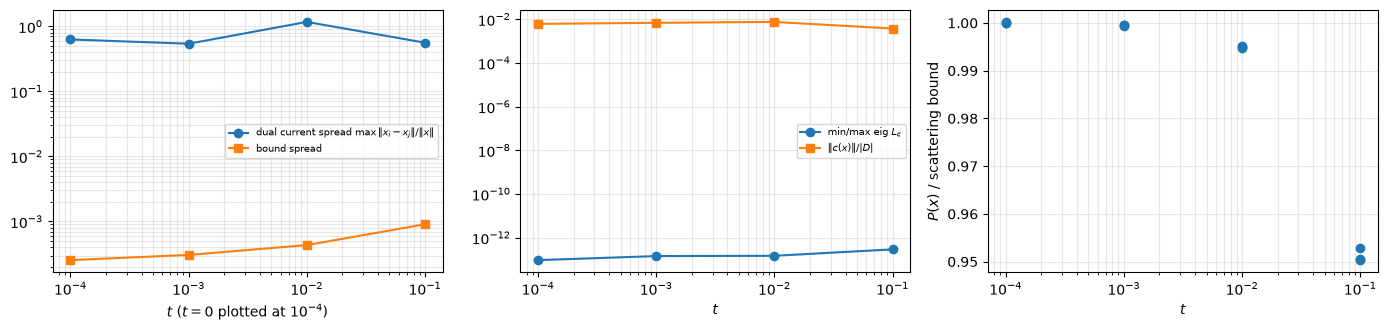

In [7]:
rows = []
for t, rs in sweep.items():
    Ds = np.array([r["D"] for r in rs])
    xsr = [r["x"] for r in rs]
    spreadX = max(np.linalg.norm(a - b)/np.linalg.norm(b) for i, a in enumerate(xsr) for b in xsr[i + 1:])
    rows.append(dict(t=t, spreadD=(Ds.max() - Ds.min())/abs(Ds.mean()), spreadX=spreadX,
                     lamRatio=np.median([r["lamRatio"] for r in rs]), res=np.median([r["res"] for r in rs]),
                     P=np.median([r["P"] for r in rs]), D=Ds.mean()))
    print(f"t {t:.0e}: bound spread {rows[-1]['spreadD']:.1e}, dual current spread {spreadX:.2e}, "
          f"median min/max eig L_c {rows[-1]['lamRatio']:.1e}, median ||c||/|D| {rows[-1]['res']:.1e}, median P {rows[-1]['P']:.4f} W")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.4))
tt = [max(r["t"], 1e-4) for r in rows]
axes[0].loglog(tt, [r["spreadX"] for r in rows], 'o-', label=r'dual current spread $\max\|x_i - x_j\| / \|x\|$')
axes[0].loglog(tt, [max(r["spreadD"], 1e-16) for r in rows], 's-', label='bound spread')
axes[0].set_xlabel(r'$t$ ($t = 0$ plotted at $10^{-4}$)'); axes[0].legend(fontsize=7)
axes[1].loglog(tt, [r["lamRatio"] for r in rows], 'o-', label=r'min/max eig $L_c$')
axes[1].loglog(tt, [r["res"] for r in rows], 's-', label=r'$\|c(x)\| / |D|$')
axes[1].set_xlabel(r'$t$'); axes[1].legend(fontsize=7)
for t, rs in sweep.items():
    axes[2].plot([max(t, 1e-4)]*len(rs), [r["P"]/Qgcd.current_dual for r in rs], 'o', c='tab:blue')
axes[2].set_xscale('log'); axes[2].set_xlabel(r'$t$'); axes[2].set_ylabel(r'$P(x)$ / scattering bound')
for ax in axes:
    ax.grid(True, which='both', alpha=0.3)
plt.tight_layout(); plt.show()

In [8]:
def complexDensity(I):
    u = Vinc - Ztot @ I + Zs*Ldiag*I
    return Zs*Ldiag*I/u

## Pointwise inference and the complex material density

As in `nullSpaceMinField.ipynb`. The complex density $d_i = Z_s L_{ii} I_i / u_i$, with $u = V - Z_\mathrm{tot} I + Z_s L_{ii} I$, is 1 on metal and 0 where the
basis function is removed. The pointwise fits project it:
- the admittance form takes $\operatorname{clip}(\operatorname{Re} d, 0, 1)$;
- the impedance form projects the series impedance onto the passive ray.

The binary design with the largest scattered power over the rounding thresholds is kept.

In [9]:
dMin = 1e-6 # basis functions with d_i < dMin are removed in the realized structure
thsLog = np.logspace(-6, 0, 61)[:-1] # thresholds for binary rounding of d

def inferDimp(I):
    # impedance form: series impedance projected onto the passive ray, d = 1/(1 + t)
    nz = I != 0
    r = np.zeros(Ndes, dtype=complex)
    r[nz] = (Vinc - Ztot @ I)[nz]/I[nz]
    t = np.maximum(0, np.real(np.conj(Zs)*r)/(np.abs(Zs)**2*Ldiag))
    return np.where(nz, 1/(1 + t), 0.0)

def inferDadm(I):
    # admittance form: real part of the complex density, clipped
    return np.clip(complexDensity(I).real, 0, 1)

def realizedCurrent(d):
    # (Ztot + diag(Zs Lii (1/d - 1))) I = V on the kept basis functions, I = 0 elsewhere
    keep = d >= dMin
    I = np.zeros(Ndes, dtype=complex)
    Zd = Ztot + np.diag(Zs*Ldiag*(1/np.maximum(d, dMin) - 1))
    I[keep] = np.linalg.solve(Zd[np.ix_(keep, keep)], Vinc[keep])
    return I

def bestBinary(d):
    designs = [d > t for t in thsLog]
    Is = [realizedCurrent(k.astype(float)) for k in designs]
    Pb = np.array([evalObj(I) for I in Is])
    k = int(np.argmax(Pb))
    return dict(keep=designs[k], I=Is[k], P=Pb[k], th=thsLog[k])

print(f"full plate: max |d - 1| = {np.abs(complexDensity(Ifull) - 1).max():.1e}")
xs = Qgcd.current_xstar
final = {f"t {t:.0e}, seed 0": sweep[t][0]["x"] for t in tSweep}
inference = {}
for name, x in final.items():
    I = VtoI(x)
    d = complexDensity(I)
    inference[name] = dict(d=d, **{form: bestBinary(infer(I)) for form, infer in [("impedance form", inferDimp), ("admittance form", inferDadm)]})
    print(f"{name:20s}: |d| quantiles 50/90/max " + "/".join(f"{q:.1e}" for q in np.quantile(np.abs(d), [0.5, 0.9, 1.0]))
          + f", |d - 1| < 0.1: {np.count_nonzero(np.abs(d - 1) < 0.1):3d}, "
          + ", ".join(f"{form} P/D {inference[name][form]['P']/Qgcd.current_dual:.4f} ({inference[name][form]['P']:.3e} W, kept {inference[name][form]['keep'].sum()})"
                      for form in ["impedance form", "admittance form"]))

full plate: max |d - 1| = 1.2e-09
t 0e+00, seed 0     : |d| quantiles 50/90/max 1.1e-04/6.5e-04/2.0e-02, |d - 1| < 0.1:   0, impedance form P/D 0.0027 (4.737e-02 W, kept 196), admittance form P/D 0.0001 (1.053e-03 W, kept 96)
t 1e-03, seed 0     : |d| quantiles 50/90/max 1.3e-04/7.2e-04/6.7e-03, |d - 1| < 0.1:   0, impedance form P/D 0.0026 (4.691e-02 W, kept 157), admittance form P/D 0.0001 (1.261e-03 W, kept 96)
t 1e-02, seed 0     : |d| quantiles 50/90/max 1.5e-04/7.2e-04/6.2e-03, |d - 1| < 0.1:   0, impedance form P/D 0.0034 (6.087e-02 W, kept 176), admittance form P/D 0.0001 (1.145e-03 W, kept 86)
t 1e-01, seed 0     : |d| quantiles 50/90/max 1.8e-04/1.4e-03/5.0e-03, |d - 1| < 0.1:   0, impedance form P/D 0.0028 (4.924e-02 W, kept 174), admittance form P/D 0.0000 (2.003e-04 W, kept 61)


### Relaxed designs (no rounding)

The structure with the relaxed density $d_i \in [0, 1]$ is solved directly in the admittance form, $(Z_\mathrm{tot} + \operatorname{diag}(Z_s L_{ii}(1/d_i - 1))) I = V$
(basis functions with $d_i < 10^{-6}$ removed). Two densities per current:
- $\operatorname{clip}(\operatorname{Re} d, 0, 1)$ of the complex density (admittance form);
- the passive projection of the series impedance (impedance form).

A density $0 < d < 1$ is a resistive sheet, so a relaxed design is not a copper structure. It shows what the inferred density achieves before
rounding.

In [10]:
def grayFraction(d):
    return np.mean((d > 0.05) & (d < 0.95))

relaxed = {}
for name, x in final.items():
    I = VtoI(x)
    dens = {"Re d clipped": inferDadm(I), "impedance form": inferDimp(I)}
    relaxed[name] = {k: dict(d=dk, P=evalObj(realizedCurrent(dk))) for k, dk in dens.items()}
    print(f"{name:42s}: dual current P/D {evalObj(I)/Qgcd.current_dual:.4f}; " + "; ".join(
        f"{k}: relaxed P/D {v['P']/Qgcd.current_dual:.4f} ({v['P']:.3e} W, gray {grayFraction(v['d']):.0%}), "
        f"binary {inference[name]['admittance form' if k == 'Re d clipped' else 'impedance form']['P']/Qgcd.current_dual:.4f}"
        for k, v in relaxed[name].items()))

t 0e+00, seed 0                           : dual current P/D 0.9999; Re d clipped: relaxed P/D 0.0000 (6.821e-04 W, gray 0%), binary 0.0001; impedance form: relaxed P/D 0.0026 (4.587e-02 W, gray 0%), binary 0.0027
t 1e-03, seed 0                           : dual current P/D 0.9993; Re d clipped: relaxed P/D 0.0001 (8.884e-04 W, gray 0%), binary 0.0001; impedance form: relaxed P/D 0.0026 (4.658e-02 W, gray 0%), binary 0.0026
t 1e-02, seed 0                           : dual current P/D 0.9953; Re d clipped: relaxed P/D 0.0001 (1.295e-03 W, gray 0%), binary 0.0001; impedance form: relaxed P/D 0.0025 (4.470e-02 W, gray 0%), binary 0.0034
t 1e-01, seed 0                           : dual current P/D 0.9528; Re d clipped: relaxed P/D 0.0000 (9.598e-05 W, gray 0%), binary 0.0000; impedance form: relaxed P/D 0.0024 (4.255e-02 W, gray 0%), binary 0.0028


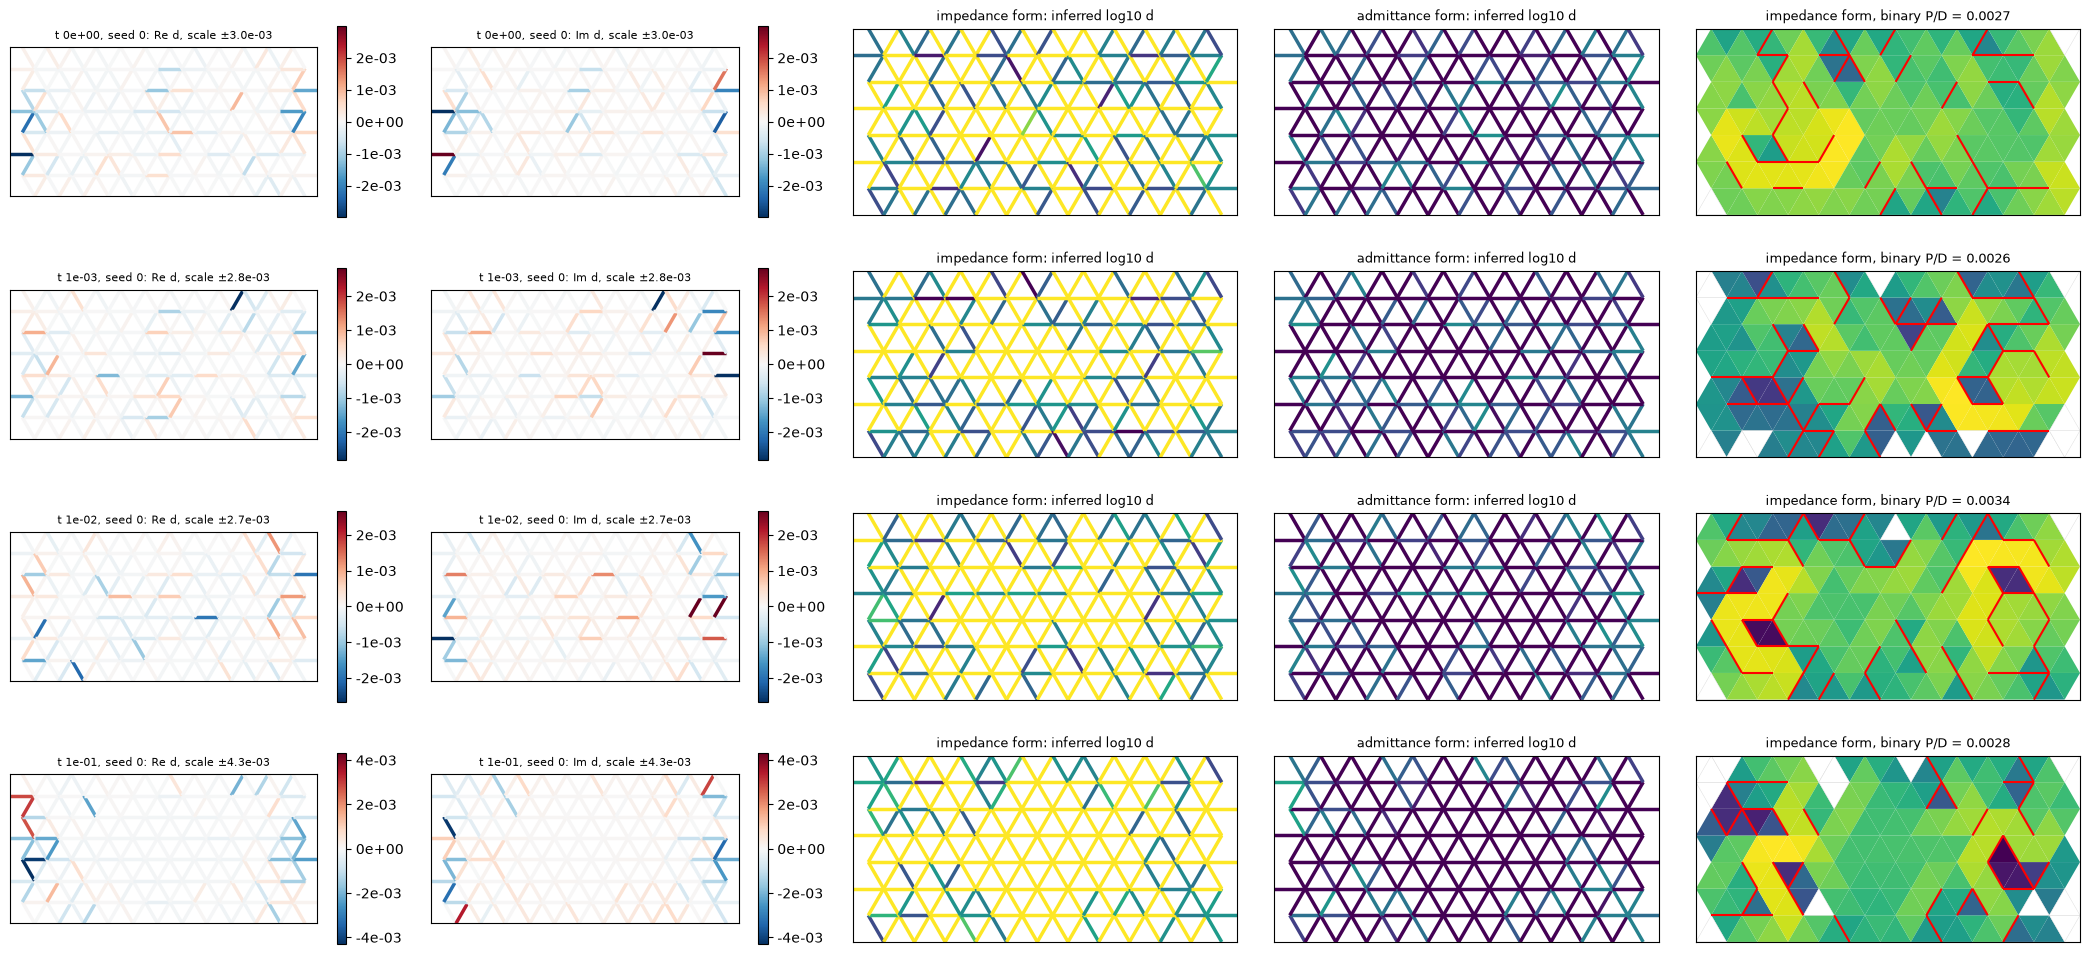

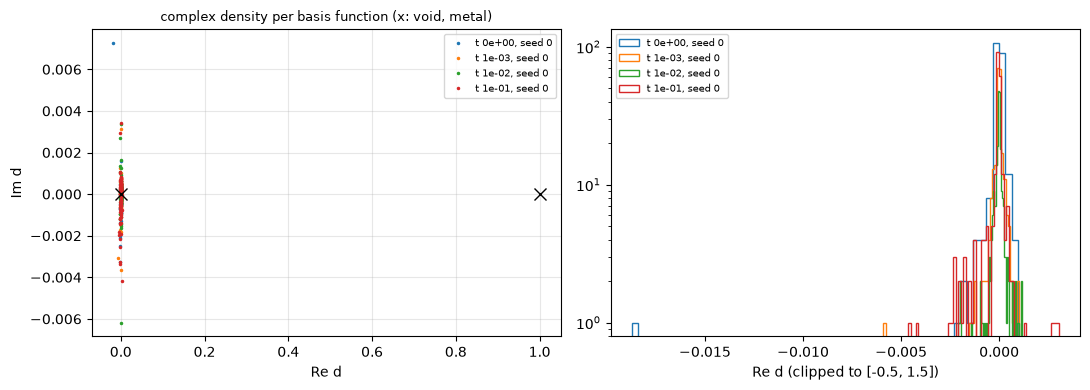

In [11]:
# final pointwise densities: real and imaginary part of the complex density, the inferred passive densities, and the binary design
names = list(inference)
fig, axes = plt.subplots(len(names), 5, figsize=(21, 2.5*len(names)))
for row, name in zip(axes, names):
    r = inference[name]
    plotComplexDensity(row[:2], r["d"], name)
    I = VtoI(final[name])
    for ax, form, infer in [(row[2], "impedance form", inferDimp), (row[3], "admittance form", inferDadm)]:
        lc = plotDensity(ax, infer(I), f"{form}: inferred log10 d")
    form = max(["impedance form", "admittance form"], key=lambda f: r[f]["P"])
    plotStructure(row[4], r[form]["keep"], r[form]["I"], f"{form}, binary P/D = {r[form]['P']/Qgcd.current_dual:.4f}")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name in names:
    d = inference[name]["d"]
    axes[0].plot(d.real, d.imag, '.', ms=3, label=name)
    axes[1].hist(np.clip(d.real, -0.5, 1.5), bins=60, histtype='step', label=name)
axes[0].plot([0, 1], [0, 0], 'kx', ms=8); axes[0].set_xlabel('Re d'); axes[0].set_ylabel('Im d'); axes[0].legend(fontsize=7)
axes[0].set_title('complex density per basis function (x: void, metal)', fontsize=9); axes[0].grid(True, alpha=0.3)
axes[1].set_yscale('log'); axes[1].set_xlabel('Re d (clipped to [-0.5, 1.5])'); axes[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

## Conclusions

_To be written after inspecting the results above._